
# Promoter Sensitivity Analysis using GFP

The goal of this simulation is to determine the minimum concentration needed to activate gene expression in our cells


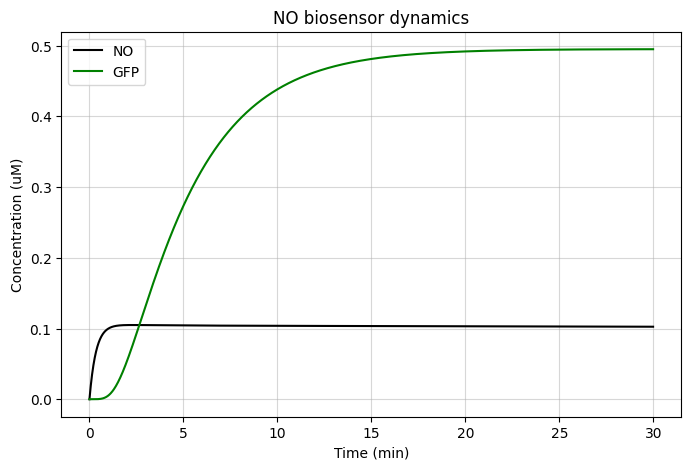

Final GFP concentration: 0.49495 uM


In [ ]:
# ------------ Base Simulation -----------------

import numpy as np
import matplotlib.pyplot as plt
# Define parameters
gamma_NO = 1.4*2
gamma_NorR = 0.3
k_syn = 0.03
k_act = 1.1183
k_in = 0.036
h = 2
K_half = 5/1000
mu = 0.0058
gamma_R = 0.376
omega = 10
chi_p = 0.3
k_release = 0.0006   # DETA to NO release rate, in 1/min
time = 30
delta_t = 0.01
time_vec = np.arange(0, time, delta_t)
num_step = np.size(time_vec)

# Initialize variables
donor = np.zeros(num_step)
donor[0] = 500   # all the NO starts locked in the donor
NO = np.zeros(num_step)
NorR = np.zeros(num_step)
NorR[0] = 0.017
NorR_active = np.zeros(num_step)
GFP = np.zeros(num_step)

for i in range(num_step-1):
  release = k_release*donor[i]

  ddonor_dt = -release
  dNO_dt = release + k_in*NorR_active[i] - (gamma_NO)*NO[i] - (k_act*NO[i]*NorR[i])
  dNorR_dt = k_syn - (gamma_NorR*NorR[i]) + k_in*NorR_active[i] - (k_act*NO[i]*NorR[i])
  dNorR_active_dt = (k_act*NO[i]*NorR[i]) - (k_in*NorR_active[i]) - (gamma_NorR*NorR_active[i])
  dGFP_dt = (omega*mu/gamma_R)*((NorR_active[i]**h)/(K_half**h + NorR_active[i]**h)) - (chi_p*GFP[i])

  donor[i+1] = donor[i] + ddonor_dt*delta_t
  NO[i+1] = NO[i] + dNO_dt*delta_t
  NorR[i+1] = NorR[i] + dNorR_dt*delta_t
  NorR_active[i+1] = NorR_active[i] + dNorR_active_dt*delta_t
  GFP[i+1] = GFP[i] + dGFP_dt*delta_t

assert min(NO.min(), NorR.min(), NorR_active.min()) >= 0, "went negative -- reduce delta_t"

fig = plt.figure(figsize=(8, 5))
plt.plot(time_vec, NO, color='black', label='NO')
plt.plot(time_vec, GFP, color='green', label='GFP')
plt.xlabel('Time (min)')
plt.ylabel('Concentration (uM)')
plt.title('NO biosensor dynamics')
plt.grid(alpha = 0.5)
plt.legend()
plt.show()
print(f"Final GFP concentration: {GFP[-1]:g} uM")

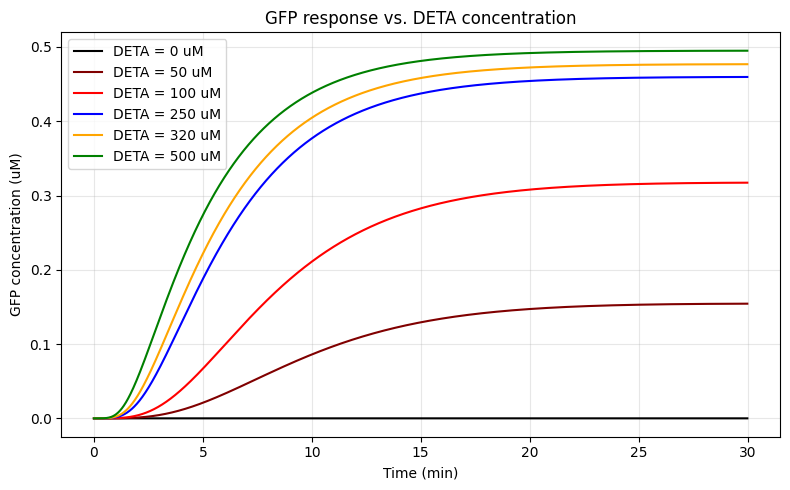

In [ ]:
# ------------ Initial DETA sweep Simulation -----------------

def simulate(donor0, NorR0=0.017):
    donor = np.zeros(num_step)
    NO = np.zeros(num_step)
    NorR = np.zeros(num_step)
    NorR_active = np.zeros(num_step)
    GFP = np.zeros(num_step)

    donor[0] = donor0
    NorR[0] = NorR0

    for i in range(num_step - 1):
        release = k_release * donor[i]

        ddonor_dt = -release
        dNO_dt = release + k_in*NorR_active[i] - gamma_NO*NO[i] - k_act*NO[i]*NorR[i]
        dNorR_dt = k_syn - gamma_NorR*NorR[i] + k_in*NorR_active[i] - k_act*NO[i]*NorR[i]
        dNorR_active_dt = k_act*NO[i]*NorR[i] - k_in*NorR_active[i] - gamma_NorR*NorR_active[i]
        dGFP_dt = (omega*mu/gamma_R) * (NorR_active[i]**h / (K_half**h + NorR_active[i]**h)) - chi_p*GFP[i]

        donor[i+1] = donor[i] + ddonor_dt*delta_t
        NO[i+1] = NO[i] + dNO_dt*delta_t
        NorR[i+1] = NorR[i] + dNorR_dt*delta_t
        NorR_active[i+1] = NorR_active[i] + dNorR_active_dt*delta_t
        GFP[i+1] = GFP[i] + dGFP_dt*delta_t

    return dict(donor=donor, NO=NO, NorR=NorR, NorR_active=NorR_active, GFP=GFP)

donor_values = [0, 50,100, 250, 320,500]   # edit as needed
t = np.arange(num_step) * delta_t
colors = ['black','maroon','red','blue','orange','green']

results = {d: simulate(d) for d in donor_values}

# Single plot: GFP for every donor value
fig, ax = plt.subplots(figsize=(8, 5))
for d, c in zip(donor_values, colors):
    ax.plot(t, results[d]["GFP"], color=c, label=f"DETA = {d} uM")
ax.set_xlabel("Time (min)")
ax.set_ylabel("GFP concentration (uM)")
ax.set_title("GFP response vs. DETA concentration")
ax.legend()
plt.grid(alpha = 0.3)
plt.tight_layout()
plt.show()

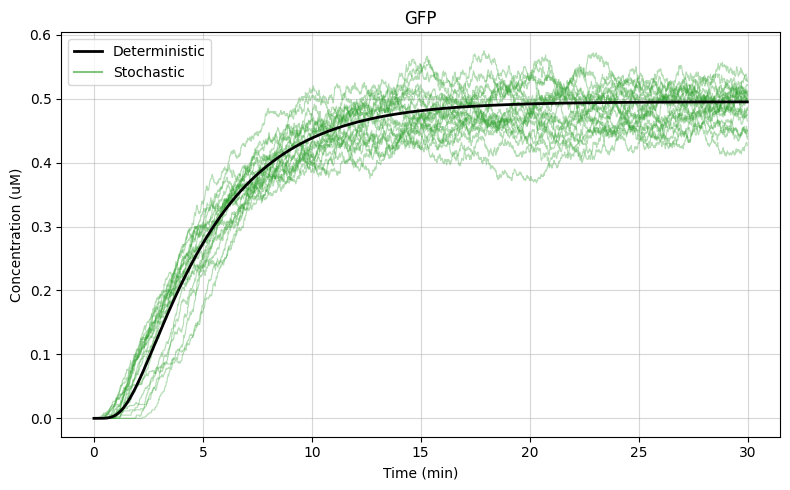

Final GFP, stochastic mean: 0.48925 uM (deterministic: 0.49495 uM)


In [ ]:
#---------Stochastic simulation-------------

import numpy as np
import matplotlib.pyplot as plt
# Define parameters
gamma_NO = 1.4*2
gamma_NorR = 0.3
k_syn = 0.03
k_act = 1.1183
k_in = 0.036
h = 2
K_half = 5/1000
mu = 0.0058
gamma_R = 0.376
omega = 10
chi_p = 0.3
k_release = 0.0006   # DETA to NO release rate, in 1/min
time = 30
delta_t = 0.01
time_vec = np.arange(0, time, delta_t)
num_step = np.size(time_vec)

# Initialize variables
donor = np.zeros(num_step)
donor[0] = 500   # all the NO starts locked in the donor
NO = np.zeros(num_step)
NorR = np.zeros(num_step)
NorR[0] = 0.017
NorR_active = np.zeros(num_step)
GFP = np.zeros(num_step)

for i in range(num_step-1):
  release = k_release*donor[i]

  ddonor_dt = -release
  dNO_dt = release + k_in*NorR_active[i] - (gamma_NO)*NO[i] - (k_act*NO[i]*NorR[i])
  dNorR_dt = k_syn - (gamma_NorR*NorR[i]) + k_in*NorR_active[i] - (k_act*NO[i]*NorR[i])
  dNorR_active_dt = (k_act*NO[i]*NorR[i]) - (k_in*NorR_active[i]) - (gamma_NorR*NorR_active[i])
  dGFP_dt = (omega*mu/gamma_R)*((NorR_active[i]**h)/(K_half**h + NorR_active[i]**h)) - (chi_p*GFP[i])

  donor[i+1] = donor[i] + ddonor_dt*delta_t
  NO[i+1] = NO[i] + dNO_dt*delta_t
  NorR[i+1] = NorR[i] + dNorR_dt*delta_t
  NorR_active[i+1] = NorR_active[i] + dNorR_active_dt*delta_t
  GFP[i+1] = GFP[i] + dGFP_dt*delta_t

assert min(NO.min(), NorR.min(), NorR_active.min()) >= 0, "went negative -- reduce delta_t"

# Define parameters
vol_scale = 600      # molecules per uM (N = C*V*A)

def gillespie(donor0=500, NO0=0, NorR0=0.017, NorR_active0=0, GFP0=0,
              max_step=500000*5, tau=0.01, tau_min=1e-4, t_stop=time):

  t = 0
  # Convert initial concentrations (uM) to molecule counts
  donor       = round(donor0*vol_scale)
  NO          = round(NO0*vol_scale)
  NorR        = round(NorR0*vol_scale)
  NorR_active = round(NorR_active0*vol_scale)
  GFP         = round(GFP0*vol_scale)

  t_vals           = [t]
  donor_vals       = [donor]
  NO_vals          = [NO]
  NorR_vals        = [NorR]
  NorR_active_vals = [NorR_active]
  GFP_vals         = [GFP]

  for step in range(max_step):
      # Hill function uses the active NorR concentration in uM
      act  = NorR_active / vol_scale
      hill = act**h / (K_half**h + act**h)

      a1 = k_release * donor                                   # NO release from donor
      a2 = k_syn * vol_scale                                   # NorR synthesis
      a3 = gamma_NorR * NorR                                   # NorR decay
      a4 = (k_act / vol_scale) * NO * NorR                     # NorR activation (consumes NO)
      a5 = k_in * NorR_active                                  # NorR deactivation (returns NO)
      a6 = gamma_NO * NO                                       # NO decay
      a7 = gamma_NorR * NorR_active                            # active NorR decay
      a8 = (omega*mu/gamma_R) * vol_scale * hill               # GFP synthesis
      a9 = chi_p * GFP                                         # GFP decay

      a  = [a1, a2, a3, a4, a5, a6, a7, a8, a9]
      a0 = np.sum(a)
      if a0 == 0:
        break

      # Try a leap of size tau_try; shrink and resample if it drives a species negative
      tau_try = tau
      while True:
        # draw firings for every channel at once
        k = [np.random.poisson(ai * tau_try) for ai in a]

        # tentative changes, applied per-branch below
        d_donor       = -k[0]
        d_NO          = k[0] - k[3] + k[4] - k[5]
        d_NorR        = k[1] - k[2] - k[3] + k[4]
        d_NorR_active = k[3] - k[4] - k[6]
        d_GFP         = k[7] - k[8]

        if (donor       + d_donor       >= 0 and
            NO          + d_NO          >= 0 and
            NorR        + d_NorR        >= 0 and
            NorR_active + d_NorR_active >= 0 and
            GFP         + d_GFP         >= 0):
          break
        tau_try *= 0.5
        if tau_try < tau_min:
          break   # give up shrinking; clamp after applying

      t += tau_try
      if t > t_stop:
        break
      t_vals.append(t)

      # ---- apply firings through the if-elif ladder ----
      # each branch now fires k[idx] times instead of once
      # (all branches run every step, since multiple channels fire per leap)
      for idx in range(len(a)):
        if idx == 0:      # a1: NO release
          donor       -= k[0]
          NO          += k[0]
        elif idx == 1:    # a2: NorR synthesis
          NorR        += k[1]
        elif idx == 2:    # a3: NorR decay
          NorR        -= k[2]
        elif idx == 3:    # a4: NorR activation
          NO          -= k[3]
          NorR        -= k[3]
          NorR_active += k[3]
        elif idx == 4:    # a5: NorR deactivation
          NorR_active -= k[4]
          NorR        += k[4]
          NO          += k[4]
        elif idx == 5:    # a6: NO decay
          NO          -= k[5]
        elif idx == 6:    # a7: active NorR decay
          NorR_active -= k[6]
        elif idx == 7:    # a8: GFP synthesis
          GFP         += k[7]
        elif idx == 8:    # a9: GFP decay
          GFP         -= k[8]

      donor       = max(donor, 0)
      NO          = max(NO, 0)
      NorR        = max(NorR, 0)
      NorR_active = max(NorR_active, 0)
      GFP         = max(GFP, 0)

      donor_vals.append(donor)
      NO_vals.append(NO)
      NorR_vals.append(NorR)
      NorR_active_vals.append(NorR_active)
      GFP_vals.append(GFP)

  return t_vals, donor_vals, NO_vals, NorR_vals, NorR_active_vals, GFP_vals

# ---- Run Gillespie and overlay on the deterministic solution ----
runs = 20
fig, ax_GFP = plt.subplots(1, 1, figsize=(8, 5))

final_GFP = []
for i in range(runs):
  t_vals, _, _, _, _, GFP_vals = gillespie(tau=0.01, tau_min=1e-4)
  # Convert counts back to uM for plotting
  ax_GFP.plot(t_vals, np.array(GFP_vals)/vol_scale, color='tab:green', alpha=0.35, lw=0.8)
  final_GFP.append(GFP_vals[-1]/vol_scale)

# Deterministic curve on top (bold black)
ax_GFP.plot(time_vec, GFP, 'k', lw=2, label='Deterministic')

# Proxy handle so the legend labels the stochastic runs
ax_GFP.plot([], [], color='tab:green', alpha=0.6, label='Stochastic')

ax_GFP.set_title('GFP')
ax_GFP.set_xlabel('Time (min)')
ax_GFP.set_ylabel('Concentration (uM)')
ax_GFP.grid(alpha=0.5)
ax_GFP.legend()

plt.tight_layout()
plt.show()
print(f"Final GFP, stochastic mean: {np.mean(final_GFP):g} uM (deterministic: {GFP[-1]:g} uM)")